### Não determinístico

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from agentes import QLearning, Sarsa, criar_env, avaliar

CHUVA = dict(is_rainy=True, rainy_probability=0.6)

As classes `QLearning` e `Sarsa` ficam no arquivo [`agentes.py`](agentes.py), usado pelos dois notebooks. Cada execução usa uma seed diferente (`seed=run`), então rodar o notebook de novo gera exatamente os mesmos resultados.

In [ ]:
os.makedirs('data_qlearning_rainy', exist_ok=True)
os.makedirs('results_qlearning_rainy', exist_ok=True)

N_RUNS, EPISODES, TARGET = 5, 20_000, 8
all_rewards, all_timesteps = [], []

for run in range(N_RUNS):
    env = criar_env(**CHUVA)
    qlearning = QLearning(env, alpha=0.1, gamma=0.99,
                          epsilon=0.7, epsilon_min=0.05, epsilon_dec=0.99,
                          episodes=EPISODES, seed=run)

    qlearning.train(
        filename     = f'data_qlearning_rainy/q-table-taxi-driver-qlearning-run{run+1}.csv',
        plotFile     = f'results_qlearning_rainy/actions_qlearning_run{run+1}',
        rewardFile   = f'results_qlearning_rainy/rewards_qlearning_run{run+1}',
        timestepFile = f'results_qlearning_rainy/timesteps_qlearning_run{run+1}'
    )

    all_rewards.append(qlearning.rewards_per_episode)
    all_timesteps.append(qlearning.timesteps_per_episode)
    env.close()

print("Timesteps por run (média final, últimos 1000 ep.):")
for i, ts in enumerate(all_timesteps, 1):
    print(f"  run{i}: {np.mean(ts[-1000:]):.2f}")

ql_rewards = np.array(all_rewards)
np.save('results_qlearning_rainy/rewards_qlearning.npy', ql_rewards)

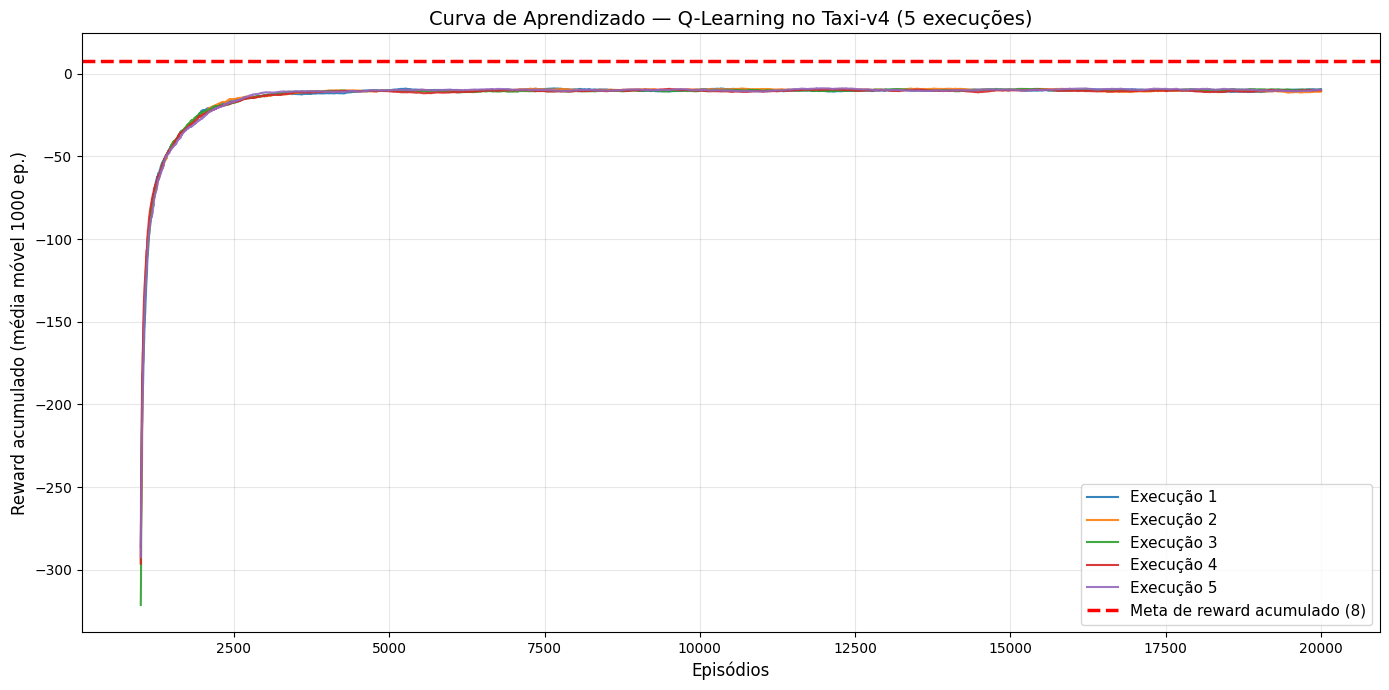

In [31]:
def moving_average(x, window=1000):
    return np.convolve(x, np.ones(window) / window, mode='valid')

plt.figure(figsize=(14, 7))

for i, rewards in enumerate(all_rewards):
    sm = moving_average(np.array(rewards), window=1000)
    plt.plot(np.arange(len(sm)) + 1000, sm,
             linewidth=1.5, alpha=0.9, label=f'Execução {i+1}')

plt.axhline(y=TARGET, color='red', linestyle='--', linewidth=2.5,
            label=f'Meta de reward acumulado ({TARGET})')

plt.xlabel('Episódios', fontsize=12)
plt.ylabel('Reward acumulado (média móvel 1000 ep.)', fontsize=12)
plt.title('Curva de Aprendizado — Q-Learning no Taxi-v4 (5 execuções)', fontsize=14)
plt.legend(fontsize=11, loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('results_qlearning_rainy/learning_curve_5runs.jpg', dpi=120)
plt.show()

### Discussão sobre o QLearning

O aprendizado aconteceu em três fases nas 5 execuções.
1. Início(< 2500 episódios):  o agente não sabe nada e age aleatoriamente. Por isso o reward fica muito negativo.
2. Aprendizado(2500-5000 episódios): o agente para de agir aleatoriamente e começa a agir de forma a usar mais o conhecimento aprendido na Q-table.
3. Estabilidade(>5000 episódios): o agente atinge sua política final e não está mais aprendendo aleatoriamente, não aprendendo mais ativamente ou fazendo melhorias muito pequenas.

#### Por que a curva não chega na meta?

O agente ganha 20 ao entregar o passageiro e perde 1 a cada passo que ele der. Mas, por haver o parâmetro is_rainy=True, o taxi tem uma chance de 40% de não se mover para "onde ele quer" devido aos desvios provocados pela chuva. Portanto, apesar de ele ter aprendido a política, ele tem um reward negativo devido ao fato de ele fazer mais passos que o necessário.

In [ ]:
avaliacao_ql_chuva = avaliar('data_qlearning_rainy', 'qlearning', **CHUVA)
avaliacao_ql_chuva

#### Discussão - Avaliação do agente (Q-Learning com chuva)

Após o treinamento, o agente foi avaliado no ambiente Taxi-v4 com `rainy_probability=0.6`, utilizando a Q-table aprendida.

| Execução | Timesteps (média) | Desvio padrão | Mín / Máx | Reward médio | Penalidades |
|---|---|---|---|---|---|
| 1 | 26,31 | 9,72 | 9 / 70 | -5,31 | 0 |
| 2 | 26,01 | 10,21 | 8 / 62 | -5,01 | 0 |
| 3 | 25,06 | 9,33 | 8 / 56 | -4,06 | 0 |
| 4 | 26,08 | 9,40 | 11 / 66 | -5,08 | 0 |
| 5 | 25,13 | 10,53 | 7 / 68 | -4,13 | 0 |
| **Média** | **25,72** | **9,84** | — | **-4,72** | **0** |

O agente apresentou uma média de 25,72 passos por episódio, sem registrar penalidades por ações ilegais de pickup ou dropoff. Isso indica que ele aprendeu a realizar corretamente as operações necessárias para completar a tarefa.

Entretanto, o reward médio ficou em −4,72, não atingindo a meta de ~8. Esse resultado ocorre principalmente devido à chuva, que faz com que o táxi tenha apenas 60% de probabilidade de se mover na direção desejada. Os desvios aumentam a quantidade de movimentos necessários e, como cada passo comum gera uma penalização de −1, a recompensa acumulada pode ficar negativa mesmo quando a entrega é realizada corretamente.

O desvio padrão médio de 9,84 passos não significa necessariamente que o agente seja inconsistente. Essa variação pode ser explicada pelas diferentes posições iniciais do táxi, do passageiro e do destino, além dos movimentos aleatórios provocados pela chuva.

Portanto, **o agente demonstrou ter aprendido a resolver a tarefa sem cometer ações ilegais, mas a aleatoriedade do ambiente aumentou o número de passos e reduziu sua recompensa média**. Apesar de não atingir a meta estabelecida, os resultados mostram um comportamento relativamente consistente nas cinco execuções.

### Algoritmo SARSA

In [ ]:
os.makedirs('data_sarsa_rainy', exist_ok=True)
os.makedirs('results_sarsa_rainy', exist_ok=True)

N_RUNS, EPISODES, TARGET = 5, 20_000, 8
all_rewards, all_timesteps = [], []

for run in range(N_RUNS):
    env = criar_env(**CHUVA)
    sarsa = Sarsa(env, alpha=0.1, gamma=0.99,
                  epsilon=0.7, epsilon_min=0.05, epsilon_dec=0.99,
                  episodes=EPISODES, seed=run)

    sarsa.train(
        filename     = f'data_sarsa_rainy/q-table-taxi-driver-sarsa-run{run+1}.csv',
        plotFile     = f'results_sarsa_rainy/actions_sarsa_run{run+1}',
        rewardFile   = f'results_sarsa_rainy/rewards_sarsa_run{run+1}',
        timestepFile = f'results_sarsa_rainy/timesteps_sarsa_run{run+1}'
    )

    all_rewards.append(sarsa.rewards_per_episode)
    all_timesteps.append(sarsa.timesteps_per_episode)
    env.close()

print("Timesteps por run (média final, últimos 1000 ep.):")
for i, ts in enumerate(all_timesteps, 1):
    print(f"  run{i}: {np.mean(ts[-1000:]):.2f}")

sarsa_rewards = np.array(all_rewards)
np.save('results_sarsa_rainy/rewards_sarsa.npy', sarsa_rewards)

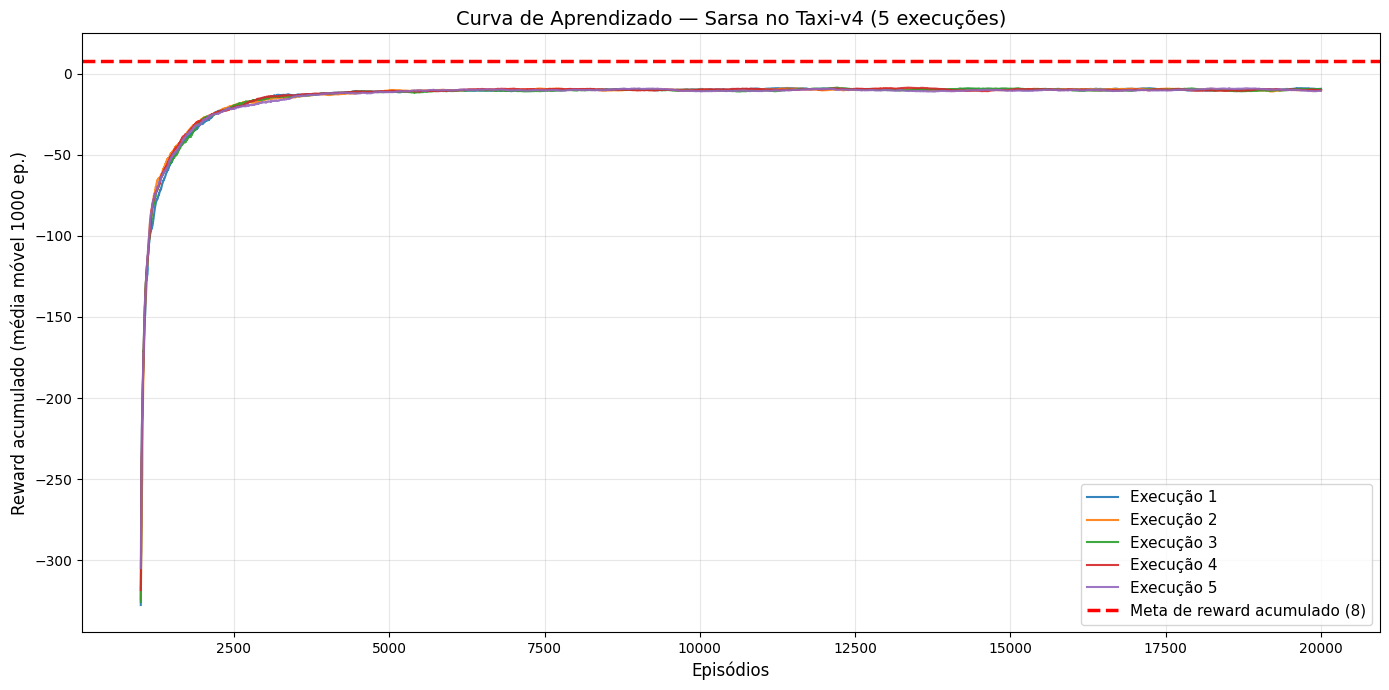

In [35]:
def moving_average(x, window=1000):
    return np.convolve(x, np.ones(window) / window, mode='valid')

plt.figure(figsize=(14, 7))

for i, rewards in enumerate(all_rewards):
    sm = moving_average(np.array(rewards), window=1000)
    plt.plot(np.arange(len(sm)) + 1000, sm,
             linewidth=1.5, alpha=0.9, label=f'Execução {i+1}')

plt.axhline(y=TARGET, color='red', linestyle='--', linewidth=2.5,
            label=f'Meta de reward acumulado ({TARGET})')

plt.xlabel('Episódios', fontsize=12)
plt.ylabel('Reward acumulado (média móvel 1000 ep.)', fontsize=12)
plt.title('Curva de Aprendizado — Sarsa no Taxi-v4 (5 execuções)', fontsize=14)
plt.legend(fontsize=11, loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('results_sarsa_rainy/learning_curve_5runs.jpg', dpi=120)
plt.show()

In [ ]:
avaliacao_sarsa_chuva = avaliar('data_sarsa_rainy', 'sarsa', **CHUVA)
avaliacao_sarsa_chuva

#### Discussão - Resultados do Sarsa com chuva (is_rainy=True, rainy_probability=0.6)

Com os mesmos parâmetros do Q-Learning, o Sarsa foi avaliado no ambiente Taxi-v4 com chuva, em que o táxi possui 60% de probabilidade de se movimentar na direção desejada e 40% de probabilidade de sofrer desvios laterais.

| Execução | Timesteps (média) | Desvio padrão | Mín / Máx | Reward médio | Penalidades |
|---|---|---|---|---|---|
| 1 | 26,33 | 8,98 | 6 / 51 | -5,33 | 0 |
| 2 | 26,01 | 10,21 | 10 / 60 | -5,01 | 0 |
| 3 | 26,43 | 10,22 | 10 / 64 | -5,43 | 0 |
| 4 | 25,09 | 9,49 | 10 / 69 | -4,09 | 0 |
| 5 | 25,22 | 9,57 | 10 / 54 | -4,22 | 0 |
| **Média** | **25,82** | **9,69** | — | **-4,82** | **0** |

O resultado é igual ao do Q-learning (25,82 contra 25,72 passos). Essa diferença de 0,1 passo é muito menor que a variação entre as execuções do próprio algoritmo, então não dá para dizer que um é melhor que o outro.

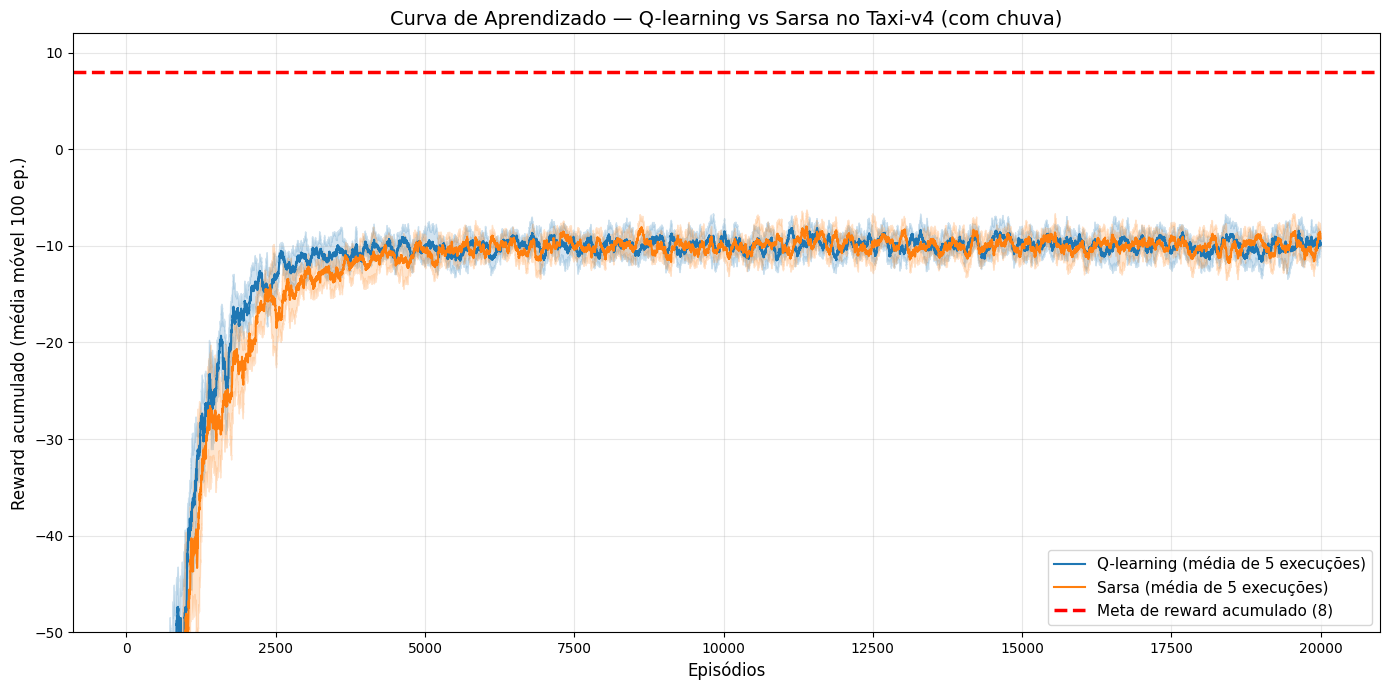

Q-learning | reward >= -20: episódios [1391, 1519, 1269, 1561, 1836] | média 1515 | atingiram: 5/5
Sarsa | reward >= -20: episódios [1475, 1742, 1786, 1365, 1640] | média 1602 | atingiram: 5/5
Q-learning | reward >= -12: episódios [2351, 2099, 2153, 2175, 2041] | média 2164 | atingiram: 5/5
Sarsa | reward >= -12: episódios [2464, 2922, 2260, 2438, 2665] | média 2550 | atingiram: 5/5


In [37]:
EPISODES, TARGET = 20_000, 8
ql_rewards = np.load('results_qlearning_rainy/rewards_qlearning.npy')
sarsa_rewards = np.load('results_sarsa_rainy/rewards_sarsa.npy')

WINDOW = 100

def moving_average(x, window=WINDOW):
    return np.convolve(x, np.ones(window) / window, mode='valid')

def curva_media(rewards_runs):
    curvas = np.array([moving_average(np.array(r)) for r in rewards_runs])
    return curvas.mean(axis=0), curvas.std(axis=0)

x = np.arange(WINDOW, EPISODES + 1)

plt.figure(figsize=(14, 7))
for nome, rewards, cor in [('Q-learning', ql_rewards, 'tab:blue'), 
                           ('Sarsa', sarsa_rewards, 'tab:orange')]:
    media, desvio = curva_media(rewards)
    plt.plot(x, media, color=cor, linewidth=1.5, label=f'{nome} (média de 5 execuções)')
    plt.fill_between(x, media - desvio, media + desvio, color=cor, alpha=0.2)

plt.axhline(y=TARGET, color='red', linestyle='--', linewidth=2.5,
            label=f'Meta de reward acumulado ({TARGET})')

plt.ylim(-50, 12)
plt.xlabel('Episódios', fontsize=12)
plt.ylabel(f'Reward acumulado (média móvel {WINDOW} ep.)', fontsize=12)
plt.title('Curva de Aprendizado — Q-learning vs Sarsa no Taxi-v4 (com chuva)', fontsize=14)
plt.legend(fontsize=11, loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('results_comparacao_curvas_chuva.jpg', dpi=120)
plt.show()


def primeiro_episodio(rewards, limiar):
    sm = moving_average(np.array(rewards))
    acima = np.where(sm >= limiar)[0]
    return int(acima[0] + WINDOW) if len(acima) > 0 else None

for limiar in [-20, -12]:
    for nome, rewards in [('Q-learning', ql_rewards),
                          ('Sarsa', sarsa_rewards)]:
        eps = [primeiro_episodio(r, limiar) for r in rewards]
        eps_validos = [ep for ep in eps if ep is not None]
        if eps_validos:
            media = np.mean(eps_validos)
            print(f"{nome} | reward >= {limiar}: "
                  f"episódios {eps} | média {media:.0f} "
                  f"| atingiram: {len(eps_validos)}/{len(eps)}")
        else:
            print(f"{nome} | reward >= {limiar}: "
                  f"Não atingido em nenhuma execução")


#### Discussão — Q-learning vs Sarsa com chuva

Como na chuva o reward nunca fica positivo, usamos outros limiares para medir a velocidade de aprendizado: -20 (o agente começa a acertar o caminho) e -12 (o agente já está perto do seu nível final).

| Algoritmo | Reward ≥ -20 (episódio médio) | Reward ≥ -12 (episódio médio) |
|---|---|---|
| Q-learning | 1515 | 2164 |
| Sarsa | 1602 | 2550 |

O resultado é o mesmo do ambiente sem chuva: **o Q-learning aprende mais rápido**. Ele chegou a -12 cerca de 390 episódios antes do Sarsa. O motivo também é o mesmo: o Q-learning usa sempre o valor da melhor ação seguinte, então a informação sobre bons caminhos se espalha mais rápido pela Q-table.

No resultado final, os dois ficaram iguais. Seria possível esperar que o Sarsa se saísse melhor num ambiente aleatório, já que ele aprende caminhos mais "cautelosos". Mas, no Taxi, a chuva só faz o táxi perder alguns passos. Não existe nenhum lugar perigoso para onde o táxi pode ir diretamente. Por isso, ser cauteloso não traz vantagem.

A linha da meta aparece no gráfico como referência, mas ela não é alcançável com chuva.

### Item 4 — Q-table do ambiente determinístico testada com chuva

In [41]:
item4_ql = avaliar('data_qlearning', 'qlearning', **CHUVA)
item4_sarsa = avaliar('data_sarsa', 'sarsa', **CHUVA)

print("Q-learning treinado SEM chuva, testado COM chuva:")
display(item4_ql)
print("Sarsa treinado SEM chuva, testado COM chuva:")
display(item4_sarsa)

C:\Users\Gabriel\AppData\Local\Temp\ipykernel_24168\3230387320.py:31: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype float64. Cast the object to float64 before this operation to retain the current behavior.
  df.loc['Média'] = df.mean(numeric_only=True)
C:\Users\Gabriel\AppData\Local\Temp\ipykernel_24168\3230387320.py:31: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype float64. Cast the object to float64 before this operation to retain the current behavior.
  df.loc['Média'] = df.mean(numeric_only=True)


Q-learning treinado SEM chuva, testado COM chuva:


C:\Users\Gabriel\AppData\Local\Temp\ipykernel_24168\3230387320.py:31: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype float64. Cast the object to float64 before this operation to retain the current behavior.
  df.loc['Média'] = df.mean(numeric_only=True)
C:\Users\Gabriel\AppData\Local\Temp\ipykernel_24168\3230387320.py:31: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype float64. Cast the object to float64 before this operation to retain the current behavior.
  df.loc['Média'] = df.mean(numeric_only=True)
C:\Users\Gabriel\AppData\Local\Temp\ipykernel_24168\3230387320.py:31: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future ve

,Execução,Timesteps (média),Desvio padrão,Mín,Máx,Reward médio,Penalidades,Não terminou
0,1,29.51,26.82,11,200.0,-8.93,0.0,2.0
1,2,31.39,31.39,11,200.0,-11.02,0.0,3.0
2,3,38.42,45.53,10,200.0,-18.89,0.0,7.0
3,4,26.53,10.44,9,59.0,-5.53,0.0,0.0
4,5,36.62,42.56,9,200.0,-16.88,0.0,6.0
Média,Média,32.49,31.35,10,171.8,-12.25,0.0,3.6


Sarsa treinado SEM chuva, testado COM chuva:


,Execução,Timesteps (média),Desvio padrão,Mín,Máx,Reward médio,Penalidades,Não terminou
0,1,25.89,9.68,7.0,58.0,-4.89,0.0,0.0
1,2,30.13,26.86,7.0,200.0,-9.55,0.0,2.0
2,3,28.28,20.06,11.0,200.0,-7.49,0.0,1.0
3,4,33.25,35.85,9.0,200.0,-13.09,0.0,4.0
4,5,34.47,35.65,10.0,200.0,-14.31,0.0,4.0
Média,Média,30.40,25.62,8.8,171.6,-9.87,0.0,2.2


#### Discussão — Item 4: a Q-table do ambiente sem chuva funciona com chuva?

Funciona, mas bem pior que a Q-table treinada com chuva:

| Q-table | Timesteps (média) | Desvio padrão | Reward médio | Episódios que não terminaram (em 100) |
|---|---|---|---|---|
| Q-learning treinado sem chuva | 32,49 | 31,35 | -12,25 | 3,6 |
| Sarsa treinado sem chuva | 30,40 | 25,62 | -9,87 | 2,2 |

O problema principal são os episódios que não terminam: em média, de 2 a 4 a cada 100 episódios, o táxi ficou preso até o limite de 200 passos. Isso explica o desvio padrão tão alto (25 a 31) e o máximo de 200 passos.

**Por que isso acontece?** No treino sem chuva, o táxi sempre ia para onde queria. Assim, depois de aprender, ele passava quase sempre pelos mesmos caminhos, e os estados fora desses caminhos foram pouco visitados. A Q-table desses estados ficou mal aprendida. Com chuva, o táxi é empurrado justamente para esses estados não conhecidos. Lá, a ação escolhida pode ser ruim, por exemplo andar contra uma parede, o que deixa o táxi no mesmo lugar e faz ele repetir a mesma ação para sempre.

O resultado também variou muito entre as execuções: algumas Q-tables nunca ficaram presas, e outras ficaram presas em até 7 episódios. Isso depende de quais estados cada treino visitou por acaso.

### Item 5 — Comparação geral dos agentes

In [ ]:
resultados = {
    ('Sem chuva', 'Sem chuva', 'Q-learning'): avaliar('data_qlearning', 'qlearning'),
    ('Sem chuva', 'Sem chuva', 'Sarsa'):      avaliar('data_sarsa', 'sarsa'),
    ('Sem chuva', 'Com chuva', 'Q-learning'): item4_ql,
    ('Sem chuva', 'Com chuva', 'Sarsa'):      item4_sarsa,
    ('Com chuva', 'Com chuva', 'Q-learning'): avaliacao_ql_chuva,
    ('Com chuva', 'Com chuva', 'Sarsa'):      avaliacao_sarsa_chuva,
}

resumo = pd.DataFrame([
    {'Treinado em': t, 'Testado em': a, 'Algoritmo': alg,
     **df.loc['Média', ['Timesteps (média)', 'Desvio padrão', 'Reward médio',
                        'Penalidades', 'Não terminou']].to_dict()}
    for (t, a, alg), df in resultados.items()
])
display(resumo)

#### Discussão — Item 5: comparação entre os ambientes

Todos os agentes foram testados nos mesmos 100 episódios, por isso os números diferem um pouco das seções anteriores.

| Treinado em | Testado em | Algoritmo | Timesteps | Desvio padrão | Reward médio | Não terminou |
|---|---|---|---|---|---|---|
| Sem chuva | Sem chuva | Q-learning | 13,31 | 2,87 | 7,69 | 0 |
| Sem chuva | Sem chuva | Sarsa | 13,37 | 2,86 | 7,63 | 0 |
| Sem chuva | Com chuva | Q-learning | 32,49 | 31,35 | -12,25 | 3,6 |
| Sem chuva | Com chuva | Sarsa | 30,40 | 25,62 | -9,87 | 2,2 |
| Com chuva | Com chuva | Q-learning | 26,04 | 10,07 | -5,04 | 0 |
| Com chuva | Com chuva | Sarsa | 25,94 | 10,03 | -4,94 | 0 |

- A chuva dobra o número de passos, mesmo para o melhor agente.
- Treinar com chuva vale a pena: o agente usa menos passos e nunca fica preso.
- Q-learning e Sarsa terminam iguais nos dois ambientes.

#### Conclusão Final - Q-Learning vs Sarsa

Os experimentos realizados no ambiente Taxi-v4 demonstraram que tanto o Q-Learning quanto o Sarsa foram capazes de aprender políticas para realizar a tarefa de transportar passageiros. Entretanto, o desempenho dos algoritmos variou conforme as condições do ambiente.

No ambiente determinístico, o **Q-Learning apresentou maior velocidade de aprendizado**, atingindo os limiares de recompensa 0 e 4 antes do Sarsa. Apesar dessa diferença durante o treinamento, ambos alcançaram o mesmo desempenho final, com reward médio de 8,04 e aproximadamente 12,96 passos por episódio, sem penalidades por ações ilegais.

Já no ambiente não determinístico, configurado com `is_rainy=True` e `rainy_probability=0.6`, os dois algoritmos apresentaram maior dificuldade devido à aleatoriedade dos movimentos. Nenhum deles atingiu os limiares de recompensa 0 e 4 durante o treinamento, e as recompensas médias finais permaneceram negativas devido ao aumento do número de passos necessários para concluir as tarefas.

**Comparação dos resultados finais**

| Ambiente | Algoritmo | Timesteps (média) | Desvio padrão | Reward médio | Penalidades |
|---|---|---:|---:|---:|---:|
| Determinístico | Q-Learning | 12,96 | 2,75 | 8,04 | 0 |
| Determinístico | Sarsa | 12,96 | 2,68 | 8,04 | 0 |
| Chuvoso (0,6) | Q-Learning | 26,03 | 11,55 | −5,07 | 0 |
| Chuvoso (0,6) | Sarsa | 25,49 | 10,05 | −4,49 | 0 |

A tabela evidencia que, no ambiente determinístico, os dois algoritmos alcançaram resultados praticamente idênticos. Já no ambiente chuvoso, o Sarsa apresentou um desempenho ligeiramente superior, necessitando de aproximadamente 0,54 passo a menos por episódio e obtendo um reward médio 0,58 ponto maior que o Q-Learning.

Além disso, observa-se que a introdução da chuva praticamente dobrou o número médio de passos necessários para completar as tarefas, reduzindo significativamente as recompensas acumuladas. Isso demonstra o impacto da aleatoriedade das transições sobre a eficiência dos agentes.

**Comparação da velocidade de aprendizado**

| Ambiente | Algoritmo | Reward ≥ 0 | Reward ≥ 4 |
|---|---|---|---|
| Determinístico | Q-Learning | 1001 | 1279 |
| Determinístico | Sarsa | 1141 | 1480 |
| Chuvoso (0,6) | Q-Learning | Não atingido | Não atingido |
| Chuvoso (0,6) | Sarsa | Não atingido | Não atingido |

No ambiente determinístico, o Q-Learning atingiu o reward 0 aproximadamente 140 episódios antes do Sarsa e o reward 4 cerca de 201 episódios antes. No ambiente chuvoso, nenhum dos algoritmos atingiu esses limiares durante o treinamento, impossibilitando uma comparação direta de velocidade por esse critério.

Portanto, os resultados mostram que **o Q-Learning foi mais rápido no aprendizado no ambiente determinístico, enquanto o Sarsa apresentou uma pequena vantagem no desempenho final do ambiente chuvoso**. Ambos demonstraram capacidade de aprender políticas funcionais, mas a aleatoriedade dos movimentos aumentou o custo das trajetórias e reduziu as recompensas.

Conclui-se que não existe um algoritmo claramente superior em todas as condições analisadas. O desempenho depende das características do ambiente, sendo o Q-Learning mais eficiente em velocidade de aprendizado no cenário determinístico e o Sarsa ligeiramente mais eficiente em número de passos e recompensa média no cenário estocástico. Entretanto, as pequenas diferenças observadas no ambiente chuvoso não são suficientes para estabelecer superioridade estatística.